# QFF2026 QML Track - Phase 2 solution: PS-Q1 (ECG heartbeat classification) + Task A + Task B

**Selected problem statement: PS-Q1.** Common tasks: **Task A** (Bell state) and **Task B** (Processor D).

- Noise model: `noise_model/benchmark_noise_model.py` (QFF2026-v2), unchanged. Every noisy circuit is passed through the official `prepare_for_noisy_run()` (basis `rx, ry, rz, cx`), one circuit at a time.
- The quantum-model code lives in `vqc_work/scripts/train_vqc.py` (single source of truth; this notebook imports it). The same script regenerates the VQC reports in `vqc_work/reports/` and has a `--selftest` mode.
- Run from the repository root (see README). Expected runtime: about 15 minutes on a 10-core laptop (training runs in parallel processes).

Sections: 0 setup - 1 Task A - 2 Task B - 3 data - 4 classical baseline - 5 quantum design - 6 training and selection - 7 seeds and ideal results - 8 ideal vs noisy, and why - 9 optional readout recalibration - 10 test predictions - 11 summary.

## 0. Setup, versions, seeds

In [1]:
import os, sys, time, json, contextlib, io
from pathlib import Path
ROOT = Path.cwd()
assert (ROOT / "data" / "q1" / "ecg_train.csv").exists(), "Run this notebook from the repository root (see README)."
for sub in ("vqc_work/scripts", "benchmark", "noise_model", "tools", "scripts"):
    sys.path.insert(0, str(ROOT / sub))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pennylane as qml, qiskit, qiskit_aer, sklearn
from IPython.display import display, Markdown
from sklearn.metrics import f1_score, roc_auc_score
import train_vqc as V
import benchmark_noise_model as bnm

SEED = V.SEED   # 42
V.seed_everything(SEED)
print(f"Python {sys.version.split()[0]} | PennyLane {qml.__version__} | Qiskit {qiskit.__version__} | Aer {qiskit_aer.__version__} | "
      f"NumPy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | noise model {bnm.VERSION}")

Python 3.13.13 | PennyLane 0.44.1 | Qiskit 2.3.0 | Aer 0.17.2 | NumPy 2.4.6 | pandas 3.1.0 | scikit-learn 1.9.1 | noise model QFF2026-v2


## 1. Task A - Bell state |Phi+>

**Fidelity definition:** F = (1 + <XX> - <YY> + <ZZ>) / 4, with <P> = (N_even - N_odd)/N, SE(<P>) = sqrt((1 - <P>^2)/N) and SE(F) = sqrt(SE_XX^2 + SE_YY^2 + SE_ZZ^2)/4, 8192 shots per basis.
P(00)+P(11) is only a population, not a fidelity. Numbers come from the official `task_a_bell()` in `benchmark/qff_qml_benchmark.py`.

In [2]:
from qff_qml_benchmark import task_a_bell
task_a = task_a_bell(shots=8192)
rows = []
for cond in ("ideal", "noisy"):
    r = task_a[cond]
    rows.append({"condition": "ideal" if cond == "ideal" else "noisy (QFF2026-v2)",
                 "<XX> +- SE": f"{r['XX']:+.4f} +- {r['XX_se']:.4f}", "<YY> +- SE": f"{r['YY']:+.4f} +- {r['YY_se']:.4f}",
                 "<ZZ> +- SE": f"{r['ZZ']:+.4f} +- {r['ZZ_se']:.4f}", "F +- SE": f"{r['fidelity']:.4f} +- {r['fidelity_se']:.4f}"})
display(pd.DataFrame(rows).set_index("condition"))
a_n = task_a["noisy"]
display(Markdown(f"""
**What the difference says about noise and entanglement.** Ideally all three correlators are exactly +-1 (XX = +1, YY = -1, ZZ = +1), so F = 1: a perfect |Phi+>.
Under the benchmark noise they shrink to {a_n['XX']:+.3f}, {a_n['YY']:+.3f} and {a_n['ZZ']:+.3f}, giving F = {a_n['fidelity']:.3f} +- {a_n['fidelity_se']:.3f}, because depolarizing errors on the H and CX gates and 2% readout flips mix the pure state toward the maximally mixed state.
ZZ degrades least because its circuit has no extra basis-change gates, while XX and YY pass through additional single-qubit gates (and S-dagger for YY) before readout.
F stays far above 0.5 (the value of a classical 50/50 mixture of |00> and |11>), so entanglement survives, but about {100 * (1 - a_n['fidelity']):.0f}% of the ideal overlap is lost after a single CX: a warning for the 16-CX classifier below.
"""))

,<XX> +- SE,<YY> +- SE,<ZZ> +- SE,F +- SE
condition,,,,
ideal,+1.0000 +- 0.0000,-1.0000 +- 0.0000,+1.0000 +- 0.0000,1.0000 +- 0.0000
noisy (QFF2026-v2),+0.8191 +- 0.0063,-0.8279 +- 0.0062,+0.8735 +- 0.0054,0.8801 +- 0.0026



**What the difference says about noise and entanglement.** Ideally all three correlators are exactly +-1 (XX = +1, YY = -1, ZZ = +1), so F = 1: a perfect |Phi+>.
Under the benchmark noise they shrink to +0.819, -0.828 and +0.874, giving F = 0.880 +- 0.003, because depolarizing errors on the H and CX gates and 2% readout flips mix the pure state toward the maximally mixed state.
ZZ degrades least because its circuit has no extra basis-change gates, while XX and YY pass through additional single-qubit gates (and S-dagger for YY) before readout.
F stays far above 0.5 (the value of a classical 50/50 mixture of |00> and |11>), so entanglement survives, but about 12% of the ideal overlap is lost after a single CX: a warning for the 16-CX classifier below.


## 2. Task B - Processor D

`processor_d_config.json` is validated and re-benchmarked live with the official tool; the stored `benchmark_results` must equal the re-run.
Design: 4-qubit ring plus one chord (0-2), every link listed in both directions, native gates `rx, ry, rz, h, cx`.

In [3]:
from qff_qml_benchmark import load_processor_d, validate_processor_d, task_b_qft3
from qiskit import transpile
from qiskit.transpiler import CouplingMap

proc_d = load_processor_d(ROOT / "processor_d_config.json")
problems = validate_processor_d(proc_d)
official = task_b_qft3(proc_d)
assert not problems, problems
assert all(proc_d["benchmark_results"][k] == v for k, v in official.items()), "stored benchmark_results differ from the official re-run"
print("processor_d_config.json is valid and its benchmark_results equal the official re-run:")
print(json.dumps(official, indent=1))

both = lambda edges: [list(x) for a, b in edges for x in ((a, b), (b, a))]
lin, ring = [(0, 1), (1, 2), (2, 3), (3, 4)], [(0, 1), (1, 2), (2, 3), (3, 0)]
designs = {
    "linear-5, one-way links": dict(n_qubits=5, coupling_map=[list(e) for e in lin], native_gate_set=["rx", "ry", "rz", "cx"]),
    "linear-5, two-way links (organizer example)": dict(n_qubits=5, coupling_map=both(lin), native_gate_set=["rx", "ry", "rz", "cx"]),
    "ring-4, two-way": dict(n_qubits=4, coupling_map=both(ring), native_gate_set=["rx", "ry", "rz", "h", "cx"]),
    "ring-4 + chord 0-2, two-way, no native h": dict(n_qubits=4, coupling_map=both(ring + [(0, 2)]), native_gate_set=["rx", "ry", "rz", "cx"]),
    "ring-4 + chord 0-2, two-way, native h (submitted)": proc_d,
}
rows = []
for name, d in designs.items():
    r = official if d is proc_d else task_b_qft3(d)
    rows.append({"design": name, "depth after": r["qft3_circuit_depth_after_transpile"], "2q gates": r["qft3_two_qubit_gate_count"],
                 "SWAP overhead": r["qft3_swap_overhead"], "noisy QFT-3 fidelity": r["qft3_fidelity_noisy"], "ideal": r["qft3_fidelity_ideal"]})
tb = pd.DataFrame(rows).set_index("design"); display(tb)

rows = []
for L in (1, 2):
    tmpl = V.qiskit_template(L)[0]
    for name, d in list(designs.items())[1:]:
        q = transpile(tmpl, coupling_map=CouplingMap(d["coupling_map"]), basis_gates=d["native_gate_set"], optimization_level=1, seed_transpiler=SEED)
        rows.append({"VQC layers": L, "processor": name, "depth": q.depth(), "CX": q.count_ops().get("cx", 0), "logical CX": 8 * L})
vqc_on_d = pd.DataFrame(rows); display(vqc_on_d)

processor_d_config.json is valid and its benchmark_results equal the official re-run:
{
 "qft3_circuit_depth_before_transpile": 6,
 "qft3_circuit_depth_after_transpile": 16,
 "qft3_two_qubit_gate_count": 9,
 "qft3_swap_overhead": 0,
 "qft3_fidelity_ideal": 1.0,
 "qft3_fidelity_noisy": 0.677499,
 "benchmark_noise_model_version": "QFF2026-v2"
}


,depth after,2q gates,SWAP overhead,noisy QFT-3 fidelity,ideal
design,,,,,
"linear-5, one-way links",31,12,1,0.550409,1.0
"linear-5, two-way links (organizer example)",22,12,1,0.603585,1.0
"ring-4, two-way",19,12,1,0.635079,1.0
"ring-4 + chord 0-2, two-way, no native h",18,9,0,0.668377,1.0
"ring-4 + chord 0-2, two-way, native h (submitted)",16,9,0,0.677499,1.0


,VQC layers,processor,depth,CX,logical CX
0,1,"linear-5, two-way links (organizer example)",15,14,8
1,1,"ring-4, two-way",12,8,8
2,1,"ring-4 + chord 0-2, two-way, no native h",12,8,8
3,1,"ring-4 + chord 0-2, two-way, native h (submitted)",12,8,8
4,2,"linear-5, two-way links (organizer example)",36,34,16
5,2,"ring-4, two-way",22,16,16
6,2,"ring-4 + chord 0-2, two-way, no native h",22,16,16
7,2,"ring-4 + chord 0-2, two-way, native h (submitted)",22,16,16


In [4]:
one, two = tb.loc["linear-5, one-way links"], tb.loc["linear-5, two-way links (organizer example)"]
rg, ours, noh = tb.loc["ring-4, two-way"], tb.loc["ring-4 + chord 0-2, two-way, native h (submitted)"], tb.loc["ring-4 + chord 0-2, two-way, no native h"]
v2 = vqc_on_d[vqc_on_d["VQC layers"] == 2].set_index("processor")
sub_name, lin_name = "ring-4 + chord 0-2, two-way, native h (submitted)", "linear-5, two-way links (organizer example)"
display(Markdown(f"""
**Interpretation: directed links, SWAPs, depth, trade-offs.**
*Directed links:* direction is enforced, so a CX on a pair listed one way is reversed with extra single-qubit gates. On the same 5-qubit line, one-way links give depth {one['depth after']} and fidelity {one['noisy QFT-3 fidelity']:.3f}; two-way links give depth {two['depth after']} and {two['noisy QFT-3 fidelity']:.3f} with the same {two['2q gates']} two-qubit gates. We therefore list every link both ways.
*SWAPs:* QFT-3 needs all three qubit pairs to interact. A plain 4-ring has no triangle, so it pays {rg['SWAP overhead']} SWAP ({rg['2q gates']} two-qubit gates, fidelity {rg['noisy QFT-3 fidelity']:.3f}). The chord 0-2 closes the triangle 0-1-2, removing the SWAP: {ours['2q gates']} two-qubit gates and fidelity {ours['noisy QFT-3 fidelity']:.4f}.
*Depth and gate set:* native `h` lowers QFT depth from {noh['depth after']} to {ours['depth after']} and raises fidelity from {noh['noisy QFT-3 fidelity']:.3f} to {ours['noisy QFT-3 fidelity']:.4f}. Nine two-qubit gates is the minimum for this decomposition (a 3-qubit triangle reaches the same value), so further links do not help the benchmark.
*Link to our PS-Q1 circuit:* the classifier uses 4 qubits and a bidirectional CX ring in every layer. On this processor the 2-layer model keeps its {int(v2.loc[sub_name, 'CX'])} CX (depth {int(v2.loc[sub_name, 'depth'])}); on the linear example it needs {int(v2.loc[lin_name, 'CX'])} CX (depth {int(v2.loc[lin_name, 'depth'])}) because ring edges must be routed. Since the classifier's noise sensitivity grows with CX count (Section 8), avoiding routing matters directly for it.
*Trade-off:* the chord is one extra coupler (more fabrication and crosstalk cost on real hardware), which the benchmark does not penalise; we stopped at one chord because a second chord gave no further benchmark gain.
"""))


**Interpretation: directed links, SWAPs, depth, trade-offs.**
*Directed links:* direction is enforced, so a CX on a pair listed one way is reversed with extra single-qubit gates. On the same 5-qubit line, one-way links give depth 31.0 and fidelity 0.550; two-way links give depth 22.0 and 0.604 with the same 12.0 two-qubit gates. We therefore list every link both ways.
*SWAPs:* QFT-3 needs all three qubit pairs to interact. A plain 4-ring has no triangle, so it pays 1.0 SWAP (12.0 two-qubit gates, fidelity 0.635). The chord 0-2 closes the triangle 0-1-2, removing the SWAP: 9.0 two-qubit gates and fidelity 0.6775.
*Depth and gate set:* native `h` lowers QFT depth from 18.0 to 16.0 and raises fidelity from 0.668 to 0.6775. Nine two-qubit gates is the minimum for this decomposition (a 3-qubit triangle reaches the same value), so further links do not help the benchmark.
*Link to our PS-Q1 circuit:* the classifier uses 4 qubits and a bidirectional CX ring in every layer. On this processor the 2-layer model keeps its 16 CX (depth 22); on the linear example it needs 34 CX (depth 36) because ring edges must be routed. Since the classifier's noise sensitivity grows with CX count (Section 8), avoiding routing matters directly for it.
*Trade-off:* the chord is one extra coupler (more fabrication and crosstalk cost on real hardware), which the benchmark does not penalise; we stopped at one chord because a second chord gave no further benchmark gain.


## 3. PS-Q1 data (training and validation only, until Section 10)

Only `ecg_train.csv` and `ecg_val.csv` are read here. The unlabelled test features are opened once, in Section 10, for inference only.

In [5]:
tr, va = V.load_data()
chk = V.integrity_checks(tr, va)
feats = chk["feature_names"]
print({k: v for k, v in chk.items() if k != "feature_names"})
assert chk["passed"]
ytr, yva = tr["label"].to_numpy(int), va["label"].to_numpy(int)
Xtr, Xva = tr[feats].to_numpy(float), va[feats].to_numpy(float)

{'train_shape': [6000, 31], 'val_shape': [1500, 31], 'n_features': 30, 'same_columns_same_order': True, 'label_column_present': True, 'sample_id_in_features': False, 'train_missing': 0, 'val_missing': 0, 'train_nonfinite': 0, 'val_nonfinite': 0, 'train_labels': {0: 3616, 1: 2384}, 'val_labels': {0: 899, 1: 601}, 'dup_rows_train': 0, 'dup_rows_val': 0, 'cross_partition_duplicate_rows': 0, 'labels_valid': True, 'passed': True}


## 4. Classical baseline (same data, tuned on validation only)

Logistic regression on standardised features (scaler fitted on train only), grid over C and class weight, selected by validation macro-F1.
Code: `scripts/train_classical_baseline.py` (the teammate's script, imported unchanged).

In [6]:
from train_classical_baseline import run_baseline_grid
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
with contextlib.redirect_stdout(io.StringIO()):
    grid, best_cfg = run_baseline_grid(ROOT / "data" / "q1" / "ecg_train.csv", ROOT / "data" / "q1" / "ecg_val.csv")
display(grid[["C", "class_weight", "train_macro_f1", "val_macro_f1", "val_accuracy"]])
sc_c = StandardScaler().fit(Xtr)
clf = LogisticRegression(C=best_cfg["C"], class_weight=None if best_cfg["class_weight"] == "None" else best_cfg["class_weight"],
                         max_iter=5000, random_state=SEED, solver="lbfgs").fit(sc_c.transform(Xtr), ytr)
pred_clf = clf.predict(sc_c.transform(Xva))
f1_clf = f1_score(yva, pred_clf, average="macro")
print(f"classical LR (C={best_cfg['C']}, class_weight={best_cfg['class_weight']}): validation macro-F1 {f1_clf:.4f} "
      f"({int((pred_clf != yva).sum())} errors of {len(yva)})")

,C,class_weight,train_macro_f1,val_macro_f1,val_accuracy
0,0.01,None,1.0,1.0,1.0
1,0.10,None,1.0,1.0,1.0
2,1.00,None,1.0,1.0,1.0
3,10.00,None,1.0,1.0,1.0
4,100.00,None,1.0,1.0,1.0
5,0.01,balanced,1.0,1.0,1.0
6,0.10,balanced,1.0,1.0,1.0
7,1.00,balanced,1.0,1.0,1.0
8,10.00,balanced,1.0,1.0,1.0
9,100.00,balanced,1.0,1.0,1.0


classical LR (C=1.0, class_weight=None): validation macro-F1 1.0000 (0 errors of 1500)


## 5. Quantum model: design and justification

**Pipeline:** 30 features -> StandardScaler -> PCA(4) -> per-component angle scaling to [-pi, pi] -> `RY` encoding on 4 qubits -> L x [trainable `RY` and `RZ` on every qubit, then CX(0,1) CX(1,0) CX(1,2) CX(2,1) CX(2,3) CX(3,2) CX(3,0) CX(0,3)] -> <Z_0> -> `logit = w <Z_0> + b` -> sigmoid, threshold 0.5.

- **4 qubits, PCA(4).** The 30 window statistics are strongly correlated; 4 components keep about 81% of the variance, and 4 qubits is the recommended range. Scaler, PCA and the angle scale are fitted on training rows only.
- **Angle scaling (key design finding).** `RY` is 2pi-periodic. Raw PCA scores reach about +-8.6 rad, so distant samples wrap onto similar rotations. Scaling each component by pi / max|train score| keeps the map one-to-one. The unscaled "direct" encoding is kept as an ablation.
- **Ansatz.** `RY` + `RZ` per qubit give general single-qubit rotations together with the encoding; the CX ring runs in both directions so that information spreads around the ring in every layer. Its 4-qubit ring is exactly the topology of Processor D (Section 2).
- **Readout.** One single-qubit expectation keeps measurement cost low; a trainable scale and bias turn it into a probability and are trained jointly.
- **Search (predeclared, not extended):** layers {1, 2} x learning rate {0.01, 0.001}; Adam; binary cross-entropy; batch 16; 30 epochs; seed 42. Selection by validation macro-F1 only (ties: fewer layers, then lr 0.001, then earlier epoch).

The structural analysis below explains what the ansatz can and cannot learn.

In [7]:
scaler, pca, angle_scale, angles, pinfo = V.fit_preprocessing(tr, va, feats)
print("PCA explained variance ratio:", np.round(pinfo["evr"], 4), "| cumulative:", np.round(pinfo["cum_evr"], 4))
print("angle scale (pi / max |train score|):", np.round(angle_scale, 4))
for enc in ("direct", "scaled"):
    print(f"{enc:>6}: training rows with an angle outside [-pi, pi]: {100 * pinfo['train_outside_pi_frac'][enc]:.1f}%")
print()
print(qml.draw(V.make_qnode(1), max_length=120)(np.zeros((1, 4)), np.zeros((1, 2, 4))))

struct = {L: V.structural_analysis(L) for L in (1, 2)}
print(f"\nCX-ring identity: <Z0> after the ring equals <Z0 Z2 Z3> before it (max error {V.heisenberg_ring_check():.1e})")
display(pd.DataFrame([{"layers": L, "quantum params": s["n_quantum_params"], "zero-gradient params": s["n_dead"],
                       "effective": s["n_effective_quantum_params"], "which": ", ".join(s["dead_params"]),
                       "mean |d<Z0>/d angle| PC1..PC4": np.round(s["input_sensitivity_mean_abs"], 3).tolist()} for L, s in struct.items()]).set_index("layers"))
display(pd.DataFrame([{"layers": L, "qubits": 4, "trainable (nominal)": 8 * L + 2, "trainable (effective)": struct[L]["n_effective_quantum_params"] + 2,
                       "logical depth": V.logical_resources(L)["depth"], "logical CX": V.logical_resources(L)["cx"]} for L in (1, 2)]).set_index("layers"))
display(Markdown("""
**What this means.** The last CX ring turns `Z_0` into `Z_0 Z_2 Z_3`, so qubit 1 never reaches the readout through the final layer, and `RZ` gates right before that ring cannot change a Z-basis result.
The 1-layer model therefore ignores PC2 entirely (its output is a product of cosines of the PC1, PC3 and PC4 angles); the 2-layer model uses all four inputs. Dead parameters never move during training; the ansatz is kept as designed and both nominal and effective counts are reported.
"""))

PCA explained variance ratio: [0.4794 0.2136 0.0703 0.0496] | cumulative: [0.4794 0.693  0.7632 0.8128]
angle scale (pi / max |train score|): [0.3658 0.4035 0.4795 0.7642]
direct: training rows with an angle outside [-pi, pi]: 52.8%
scaled: training rows with an angle outside [-pi, pi]: 0.0%

0: ──RY(M0)──RY(0.00)──RZ(0.00)─╭●─╭X─────────────╭X─╭●─┤  <Z>
1: ──RY(M0)──RY(0.00)──RZ(0.00)─╰X─╰●─╭●─╭X───────│──│──┤     
2: ──RY(M0)──RY(0.00)──RZ(0.00)───────╰X─╰●─╭●─╭X─│──│──┤     
3: ──RY(M0)──RY(0.00)──RZ(0.00)─────────────╰X─╰●─╰●─╰X─┤     

M0 = 
[0.]

CX-ring identity: <Z0> after the ring equals <Z0 Z2 Z3> before it (max error 1.2e-16)


,quantum params,zero-gradient params,effective,which,mean |d<Z0>/d angle| PC1..PC4
layers,,,,,
1,8,5,3,"layer0_RY_q1, layer0_RZ_q0, layer0_RZ_q1, laye...","[0.251, 0.0, 0.248, 0.275]"
2,16,6,10,"layer0_RZ_q2, layer1_RY_q1, layer1_RZ_q0, laye...","[0.081, 0.101, 0.089, 0.088]"


,qubits,trainable (nominal),trainable (effective),logical depth,logical CX
layers,,,,,
1,4,10,5,11,8
2,4,18,12,21,16



**What this means.** The last CX ring turns `Z_0` into `Z_0 Z_2 Z_3`, so qubit 1 never reaches the readout through the final layer, and `RZ` gates right before that ring cannot change a Z-basis result.
The 1-layer model therefore ignores PC2 entirely (its output is a product of cosines of the PC1, PC3 and PC4 angles); the 2-layer model uses all four inputs. Dead parameters never move during training; the ansatz is kept as designed and both nominal and effective counts are reported.


## 6. Training and model selection (both encodings, predeclared grid, 8 runs in parallel)

search: 211 s wall


,encoding,layers,lr,best epoch,best val macro-F1,final train loss,forward circuit evals,"train time (s, parallel)",selected
0,scaled,1,0.010,4,0.9667,0.0806,405000,142,
1,scaled,1,0.001,19,0.9660,0.0938,405000,142,
2,scaled,2,0.010,3,0.9993,0.0003,405000,207,
3,scaled,2,0.001,19,0.9993,0.0144,405000,208,<-
4,direct,1,0.010,6,0.8855,0.3056,405000,142,
5,direct,1,0.001,30,0.8806,0.3048,405000,142,
6,direct,2,0.010,23,0.9633,0.1276,405000,207,<-
7,direct,2,0.001,17,0.9511,0.1467,405000,207,


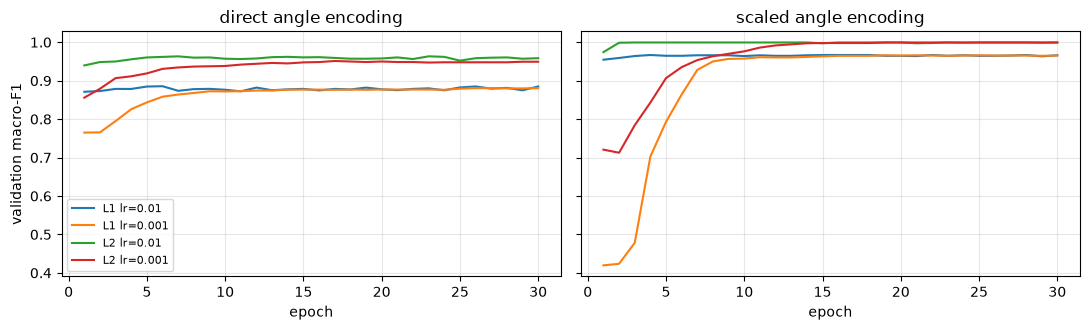

canonical model: scaled_L2_lr0.001_s42 at epoch 19 (validation macro-F1 0.9993)


In [8]:
def job(enc, L, lr, seed):
    return {"cfg_id": f"{enc}_L{L}_lr{lr}_s{seed}", "encoding": enc, "n_layers": L, "lr": lr, "Atr": angles[enc][0], "ytr": ytr,
            "Ava": angles[enc][1], "yva": yva, "seed": seed}
t0 = time.time()
search = V.run_parallel([job(e, L, lr, SEED) for e in V.ENCODINGS for L in V.LAYER_GRID for lr in V.LR_GRID])
print(f"search: {time.time() - t0:.0f} s wall")
by_enc = {e: [r for r in search if r["encoding"] == e] for e in V.ENCODINGS}
sel = {e: V.select_final(rs) for e, rs in by_enc.items()}
sel_L1 = V.select_final([r for r in by_enc["scaled"] if r["layers"] == 1])
canon = sel["scaled"]; Lc = canon["layers"]; params = canon["best"]["params"]
display(pd.DataFrame([{"encoding": r["encoding"], "layers": r["layers"], "lr": r["lr"], "best epoch": r["best"]["epoch"],
                       "best val macro-F1": round(r["best"]["val_macro_f1"], 4), "final train loss": round(r["history"][-1]["train_loss"], 4),
                       "forward circuit evals": r["forward_evals"], "train time (s, parallel)": round(r["train_time_s"]),
                       "selected": "<-" if r is sel[r["encoding"]] else ""} for r in search]))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, e in zip(axes, ("direct", "scaled")):
    for r in by_enc[e]:
        ax.plot([h["epoch"] for h in r["history"]], [h["val_macro_f1"] for h in r["history"]], label=f"L{r['layers']} lr={r['lr']}")
    ax.set_title(f"{e} angle encoding"); ax.set_xlabel("epoch"); ax.grid(alpha=.3)
axes[0].set_ylabel("validation macro-F1"); axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()
print(f"canonical model: {canon['cfg_id']} at epoch {canon['best']['epoch']} (validation macro-F1 {canon['best']['val_macro_f1']:.4f})")

## 7. Seeds, confidence intervals, ideal results

The seed controls initial parameters and mini-batch order; the selected configuration of each encoding is retrained with seeds 43-46. Ideal results are exact statevector expectations.
Validation also chose the epoch, configuration and encoding, so these are model-selection numbers (optimistic), not held-out evidence.

In [9]:
t0 = time.time()
seed_runs = V.run_parallel([job(e, sel[e]["layers"], sel[e]["lr"], s) for e in V.ENCODINGS for s in V.EXTRA_SEEDS])
print(f"seed runs: {time.time() - t0:.0f} s wall")
display(pd.DataFrame([{"encoding": e, "config": f"L{sel[e]['layers']} lr={sel[e]['lr']}",
                       "best val macro-F1, seeds 42-46": np.round([sel[e]["best"]["val_macro_f1"]] + [r["best"]["val_macro_f1"] for r in seed_runs if r["encoding"] == e], 4).tolist()}
                      for e in V.ENCODINGS]).set_index("encoding"))
models = {"canonical: scaled, 2 layers": ("scaled", canon), "ablation: direct, 2 layers": ("direct", sel["direct"]), "diagnostic: scaled, 1 layer": ("scaled", sel_L1)}
ideal = {}
for name, (enc, s) in models.items():
    L = s["layers"]
    lg, z = V.ideal_logits(V.make_qnode(L), s["best"]["params"], L, angles[enc][1])
    pred = (lg >= 0).astype(int)
    ideal[name] = {"logit": lg, "z": z, "m": V.compute_metrics(yva, lg), "ci": V.bootstrap_ci(yva, pred), "auc": roc_auc_score(yva, lg)}
rows = [{"model": "classical logistic regression (30 features)", "val macro-F1": round(f1_clf, 4), "95% CI": "[1.0000, 1.0000]" if f1_clf == 1 else "", "accuracy": round((pred_clf == yva).mean(), 4)}]
rows += [{"model": k, "val macro-F1": round(d["m"]["macro_f1"], 4), "95% CI": f"[{d['ci'][0]:.4f}, {d['ci'][1]:.4f}]", "accuracy": round(d["m"]["accuracy"], 4)} for k, d in ideal.items()]
display(pd.DataFrame(rows).set_index("model"))
m = ideal["canonical: scaled, 2 layers"]["m"]
print("canonical per class:", {k: round(m[k], 4) for k in ("precision_0", "recall_0", "f1_0", "precision_1", "recall_1", "f1_1")},
      "| confusion [[tn, fp], [fn, tp]] =", [[m["tn"], m["fp"]], [m["fn"], m["tp"]]])

seed runs: 224 s wall


,config,"best val macro-F1, seeds 42-46"
encoding,,
scaled,L2 lr=0.001,"[0.9993, 0.9993, 0.9993, 0.9993, 0.9993]"
direct,L2 lr=0.01,"[0.9633, 0.9647, 0.9639, 0.9633, 0.9626]"


,val macro-F1,95% CI,accuracy
model,,,
classical logistic regression (30 features),1.0000,"[1.0000, 1.0000]",1.0000
"canonical: scaled, 2 layers",0.9993,"[0.9979, 1.0000]",0.9993
"ablation: direct, 2 layers",0.9633,"[0.9534, 0.9727]",0.9647
"diagnostic: scaled, 1 layer",0.9667,"[0.9570, 0.9751]",0.9680


canonical per class: {'precision_0': 1.0, 'recall_0': 0.9989, 'f1_0': 0.9994, 'precision_1': 0.9983, 'recall_1': 1.0, 'f1_1': 0.9992} | confusion [[tn, fp], [fn, tp]] = [[898, 1], [0, 601]]


## 8. Ideal vs noisy (official QFF2026-v2), and why

The **same trained weights** run on all 1,500 validation inputs: each bound circuit goes through `prepare_for_noisy_run()`, then 8,192 shots on `noisy_simulator(seed)` for seeds 42-46.
<Z_0> = (n0 - n1)/shots from the measured qubit-0 bit, then the same trained readout. The checks first prove that the noise is applied and the executed circuits equal the trained ones.

{
 "bitorder_x_on_q0": {
  "z0": -1.0,
  "expected": -1.0,
  "ok": true
 },
 "bitorder_x_on_q1": {
  "z0": 1.0,
  "expected": 1.0,
  "ok": true
 },
 "readout_noise_empty_circuit": {
  "p_read_1": 0.01806640625,
  "expected": 0.02,
  "se": 0.0015467960838455727,
  "ok": true
 },
 "simulator_has_noise_model": true,
 "qiskit_statevector_vs_pennylane_max_diff": 1.2212453270876722e-15,
 "transpiled_statevector_vs_pennylane_max_diff": 1.1102230246251565e-15,
 "shots_noiseless_vs_exact": {
  "n": 300,
  "max_abs_diff": 0.028443663796774765,
  "mean_abs_diff": 0.006278657067622624,
  "shot_sigma": 0.011048543456039804,
  "ok": true
 },
 "noisy_vs_exact_subset": {
  "n": 300,
  "mean_abs_diff": 0.3281630104625947,
  "mean_abs_z_exact": 0.5389142902678192,
  "mean_abs_z_noisy": 0.21341471354166666
 },
 "all_ok": true
}


model,"canonical: scaled, 2 layers","ablation: direct, 2 layers","diagnostic: scaled, 1 layer"
CX,16,16,8
transpiled depth,21,21,11
ideal macro-F1,0.9993,0.9633,0.9667
noisy macro-F1 (seed 42),0.4731,0.7993,0.9487
noisy mean +- sd (5 seeds),0.4663 +- 0.0048,0.7971 +- 0.0037,0.9496 +- 0.0013
noisy recall Normal,0.192,0.665,0.925
noisy recall Arrhythmia,1.0,1.0,0.987
ROC-AUC ideal,1.0,0.9921,0.994
ROC-AUC noisy,1.0,0.9911,0.9938
<Z0> shrink (slope),0.396,0.38,0.599


canonical noisy confusion (seed 42) [[tn, fp], [fn, tp]] = [[173, 726], [0, 601]]


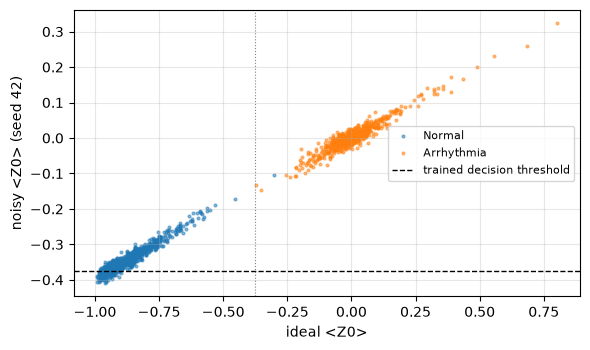

In [10]:
ver = V.noise_verification(bnm, Lc, params, angles["scaled"][1])
print(json.dumps({k: ver[k] for k in ("bitorder_x_on_q0", "bitorder_x_on_q1", "readout_noise_empty_circuit", "simulator_has_noise_model",
                                      "qiskit_statevector_vs_pennylane_max_diff", "transpiled_statevector_vs_pennylane_max_diff",
                                      "shots_noiseless_vs_exact", "noisy_vs_exact_subset", "all_ok")}, indent=1, default=str))
assert ver["all_ok"]
noisy, rows = {}, []
for name, (enc, s) in models.items():
    L, p = s["layers"], s["best"]["params"]
    ev = V.noisy_evaluation(bnm, L, p, angles[enc][1], yva)
    assert not ev["transpile"]["ops_outside_basis"] and not ev["transpile"]["unnoised_gates"]
    zi = ideal[name]["z"]
    ev["slope"] = float(np.polyfit(zi, ev["z"], 1)[0]); ev["corr"] = float(np.corrcoef(zi, ev["z"])[0, 1]); ev["auc"] = roc_auc_score(yva, ev["logit"])
    ev["thr"] = float(-p[8 * L + 1] / p[8 * L])
    noisy[name] = ev
    rows.append({"model": name, "CX": 8 * L, "transpiled depth": ev["transpile"]["depth_max"], "ideal macro-F1": round(ideal[name]["m"]["macro_f1"], 4),
                 "noisy macro-F1 (seed 42)": round(ev["metrics"]["macro_f1"], 4), "noisy mean +- sd (5 seeds)": f"{ev['macro_f1_mean']:.4f} +- {ev['macro_f1_sd']:.4f}",
                 "noisy recall Normal": round(ev["metrics"]["recall_0"], 3), "noisy recall Arrhythmia": round(ev["metrics"]["recall_1"], 3),
                 "ROC-AUC ideal": round(ideal[name]["auc"], 4), "ROC-AUC noisy": round(ev["auc"], 4), "<Z0> shrink (slope)": round(ev["slope"], 3),
                 "corr(ideal, noisy)": round(ev["corr"], 4), "threshold in <Z0>": round(ev["thr"], 3), "shots": f"{ev['total_shots']:,}"})
display(pd.DataFrame(rows).set_index("model").T)
n = noisy["canonical: scaled, 2 layers"]
print("canonical noisy confusion (seed 42) [[tn, fp], [fn, tp]] =", [[n["metrics"]["tn"], n["metrics"]["fp"]], [n["metrics"]["fn"], n["metrics"]["tp"]]])
fig, ax = plt.subplots(figsize=(6, 3.6))
ci_ = ideal["canonical: scaled, 2 layers"]["z"]
ax.scatter(ci_[yva == 0], n["z"][yva == 0], s=4, alpha=.5, label="Normal"); ax.scatter(ci_[yva == 1], n["z"][yva == 1], s=4, alpha=.5, label="Arrhythmia")
ax.axhline(n["thr"], color="k", lw=1, ls="--", label="trained decision threshold"); ax.axvline(n["thr"], color="grey", lw=.8, ls=":")
ax.set_xlabel("ideal <Z0>"); ax.set_ylabel("noisy <Z0> (seed 42)"); ax.legend(fontsize=8); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

In [11]:
n, n1, nd = noisy["canonical: scaled, 2 layers"], noisy["diagnostic: scaled, 1 layer"], noisy["ablation: direct, 2 layers"]
i_, i1, id_ = ideal["canonical: scaled, 2 layers"], ideal["diagnostic: scaled, 1 layer"], ideal["ablation: direct, 2 layers"]
display(Markdown(f"""
**How noise changes macro-F1, and why.**
- *Attenuation, not scrambling.* For the canonical model the noisy <Z_0> is close to {n['slope']:.2f} x the ideal value (correlation {n['corr']:.4f}); the ranking survives (ROC-AUC {i_['auc']:.4f} ideal, {n['auc']:.4f} noisy). Depolarizing errors on 16 CX gates (5% each), single-qubit gates (1%) and 2% readout flips shrink every expectation toward 0.
- *A fixed threshold breaks.* The trained readout decides at <Z_0> = {n['thr']:+.3f}, learned for the full-strength signal. After shrinkage most Normal beats land on the Arrhythmia side (scatter plot): noisy recall Normal {n['metrics']['recall_0']:.3f}, Arrhythmia {n['metrics']['recall_1']:.3f}, macro-F1 {i_['m']['macro_f1']:.4f} -> {n['macro_f1_mean']:.4f} (5 seeds). The information survives; the calibration of the decision rule does not.
- *Depth trade-off.* The 1-layer model (8 CX) is shrunk less ({n1['slope']:.2f}x) and keeps {n1['macro_f1_mean']:.4f} under noise, but is weaker ideally ({i1['m']['macro_f1']:.4f}) and, structurally, blind to PC2. The direct-angle ablation goes from {id_['m']['macro_f1']:.4f} to {nd['macro_f1_mean']:.4f}.
- *Takeaway.* The best ideal model is the most noise-fragile one; on this noise model, every extra CX layer trades ideal accuracy for robustness.
"""))


**How noise changes macro-F1, and why.**
- *Attenuation, not scrambling.* For the canonical model the noisy <Z_0> is close to 0.40 x the ideal value (correlation 0.9977); the ranking survives (ROC-AUC 1.0000 ideal, 1.0000 noisy). Depolarizing errors on 16 CX gates (5% each), single-qubit gates (1%) and 2% readout flips shrink every expectation toward 0.
- *A fixed threshold breaks.* The trained readout decides at <Z_0> = -0.375, learned for the full-strength signal. After shrinkage most Normal beats land on the Arrhythmia side (scatter plot): noisy recall Normal 0.192, Arrhythmia 1.000, macro-F1 0.9993 -> 0.4663 (5 seeds). The information survives; the calibration of the decision rule does not.
- *Depth trade-off.* The 1-layer model (8 CX) is shrunk less (0.60x) and keeps 0.9496 under noise, but is weaker ideally (0.9667) and, structurally, blind to PC2. The direct-angle ablation goes from 0.9633 to 0.7971.
- *Takeaway.* The best ideal model is the most noise-fragile one; on this noise model, every extra CX layer trades ideal accuracy for robustness.


## 9. Optional mitigation: readout recalibration under noise (not used for the predictions)

Because the noisy ranking survives, re-fitting only the 1-D readout (`w`, `b`) on noisy validation outputs should recover most of the loss. Circuit weights stay fixed.
The estimate is out-of-fold (5-fold on validation), so no sample is scored by a readout fitted on it. Extra cost: none beyond the noisy validation run already done (1,500 circuits x 8,192 shots); it assumes the device noise stays the same at deployment and it uses validation labels.

In [12]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
rows = []
for name, ev in noisy.items():
    oof = cross_val_predict(LogisticRegression(C=1e4, max_iter=1000), ev["z"].reshape(-1, 1), yva, cv=cv)
    rows.append({"model": name, "ideal": round(ideal[name]["m"]["macro_f1"], 4), "noisy, trained readout": round(ev["metrics"]["macro_f1"], 4),
                 "noisy, readout re-fitted (5-fold OOF)": round(f1_score(yva, oof, average="macro"), 4)})
display(pd.DataFrame(rows).set_index("model"))

,ideal,"noisy, trained readout","noisy, readout re-fitted (5-fold OOF)"
model,,,
"canonical: scaled, 2 layers",0.9993,0.4731,0.9986
"ablation: direct, 2 layers",0.9633,0.7993,0.9612
"diagnostic: scaled, 1 layer",0.9667,0.9487,0.9640


## 10. Predictions for the hidden test set

The test features are opened here for the first time, for **inference only**: scaler, PCA, angle scale and circuit weights were all fixed above from training data (configuration and epoch from validation).
Predictions come from the canonical model under **ideal (exact statevector) simulation**; its noisy behaviour is reported in Section 8. `sample_id` is copied, never used as a feature.

In [13]:
test = pd.read_csv(ROOT / "data" / "q1" / "ecg_test_features.csv")
assert list(test.columns) == ["sample_id"] + feats and len(test) == 1500
A_test = pca.transform(scaler.transform(test[feats].to_numpy(float))) * angle_scale
lg_test, _ = V.ideal_logits(V.make_qnode(Lc), params, Lc, A_test)
pred_df = pd.DataFrame({"sample_id": test["sample_id"], "label": (lg_test >= 0).astype(int)})
pred_df.to_csv(ROOT / "predictions_q1.csv", index=False)
from validate_predictions import validate
errs = validate("q1", str(ROOT / "predictions_q1.csv"))
print("validator:", errs or "OK - predictions file is valid")
assert not errs
agree = (pred_df["label"].to_numpy() == clf.predict(sc_c.transform(test[feats].to_numpy(float)))).mean()
print("predicted class counts:", pred_df["label"].value_counts().sort_index().to_dict(),
      f"| agreement with the classical baseline's test predictions (sanity check, no labels involved): {agree:.4f}")

validator: OK - predictions file is valid
predicted class counts: {0: 885, 1: 615} | agreement with the classical baseline's test predictions (sanity check, no labels involved): 1.0000


## 11. Summary

In [14]:
summary = pd.DataFrame([
    {"model": "classical logistic regression", "val macro-F1 ideal": round(f1_clf, 4), "val macro-F1 noisy (5 seeds)": "n/a"},
    *[{"model": k, "val macro-F1 ideal": round(ideal[k]["m"]["macro_f1"], 4), "val macro-F1 noisy (5 seeds)": f"{noisy[k]['macro_f1_mean']:.4f} +- {noisy[k]['macro_f1_sd']:.4f}"} for k in models],
]).set_index("model")
display(summary)
print(f"Task A noisy F = {task_a['noisy']['fidelity']:.4f} +- {task_a['noisy']['fidelity_se']:.4f} | Task B noisy QFT-3 F = {official['qft3_fidelity_noisy']}")
print(f"Training cost: {sum(r['forward_evals'] for r in search + seed_runs):,} forward circuit evaluations (exact simulation, backprop gradients); "
      f"noisy evaluation: 3 models x 1,500 circuits x 8,192 shots x 5 seeds = {3 * 1500 * 8192 * 5:,} shots.")

,val macro-F1 ideal,val macro-F1 noisy (5 seeds)
model,,
classical logistic regression,1.0000,n/a
"canonical: scaled, 2 layers",0.9993,0.4663 +- 0.0048
"ablation: direct, 2 layers",0.9633,0.7971 +- 0.0037
"diagnostic: scaled, 1 layer",0.9667,0.9496 +- 0.0013


Task A noisy F = 0.8801 +- 0.0026 | Task B noisy QFT-3 F = 0.677499
Training cost: 6,480,000 forward circuit evaluations (exact simulation, backprop gradients); noisy evaluation: 3 models x 1,500 circuits x 8,192 shots x 5 seeds = 184,320,000 shots.
